In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, io, json, shutil, hashlib, numpy as np, polars as pl
import matplotlib.pyplot as plt
from datasets import load_dataset, Image as HFImage
from PIL import Image, ImageOps
from multiprocessing import Pool
from numpy.lib.format import open_memmap
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

OUT = '/content/drive/MyDrive/uczenie_nienadzorowane/data/huggan'
LOCAL_NPY = '/content/images.npy'
os.makedirs(OUT, exist_ok=True)
SIZE, SEED = 256, 42
COLS = ['artist', 'genre', 'style']

ds = load_dataset('huggan/wikiart', split='train', streaming=True)
ds = ds.cast_column('image', HFImage(decode=False))
N = ds.info.splits['train'].num_examples
names = {c: ds.features[c].names for c in COLS}
print('N =', N, '| klas:', {c: len(v) for c, v in names.items()})
print('Wolne na dysku Colaba [GB]:', round(shutil.disk_usage('/content').free / 1e9, 1))

Mounted at /content/drive


README.md:   0%|          | 0.00/2.37k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/72 [00:00<?, ?it/s]

dataset_infos.json:   0%|          | 0.00/5.91k [00:00<?, ?B/s]

N = 81444 | klas: {'artist': 129, 'genre': 11, 'style': 27}
Wolne na dysku Colaba [GB]: 220.4


In [ ]:
def to_256(b):
    img = Image.open(io.BytesIO(b))
    img.draft('RGB', (2 * SIZE, 2 * SIZE))
    return np.asarray(ImageOps.fit(img.convert('RGB'), (SIZE, SIZE), Image.BICUBIC))

images = open_memmap(LOCAL_NPY, mode='w+', dtype=np.uint8, shape=(N, SIZE, SIZE, 3))
lab = {c: [] for c in COLS}
pos = 0
with Pool() as pool:
    for batch in tqdm(ds.iter(batch_size=1000), total=-(-N // 1000)):
        arrs = pool.map(to_256, [im['bytes'] for im in batch['image']], chunksize=32)
        images[pos:pos + len(arrs)] = np.stack(arrs)
        for c in COLS:
            lab[c].extend(batch[c])
        pos += len(arrs)
images.flush()
assert pos == N, (pos, N)
print('Gotowe:', pos, 'obrazów')

  0%|          | 0/82 [00:00<?, ?it/s]

Gotowe: 81444 obrazów


In [ ]:
labels = pl.DataFrame({'idx': np.arange(N), **{c: np.array(lab[c]) for c in COLS}})
labels.write_csv(f'{OUT}/labels.csv')
with open(f'{OUT}/label_names.json', 'w') as f:
    json.dump(names, f)

y = labels['style'].to_numpy()
idx = np.arange(N)
tr, tmp = train_test_split(idx, test_size=0.2, stratify=y, random_state=SEED)
va, te = train_test_split(tmp, test_size=0.5, stratify=y[tmp], random_state=SEED)
split = {'train': np.sort(tr), 'val': np.sort(va), 'test': np.sort(te)}
np.savez(f'{OUT}/split_seed{SEED}.npz', **split)

checksum = hashlib.md5(np.concatenate(list(split.values())).tobytes()).hexdigest()
print({k: len(v) for k, v in split.items()}, '| checksum:', checksum)

{'train': 65155, 'val': 8144, 'test': 8145} | checksum: 4b6076fe4ae00f44bdc7dfde4edb2c8f


Maks. różnica udziału stylu train-test: 0.0001


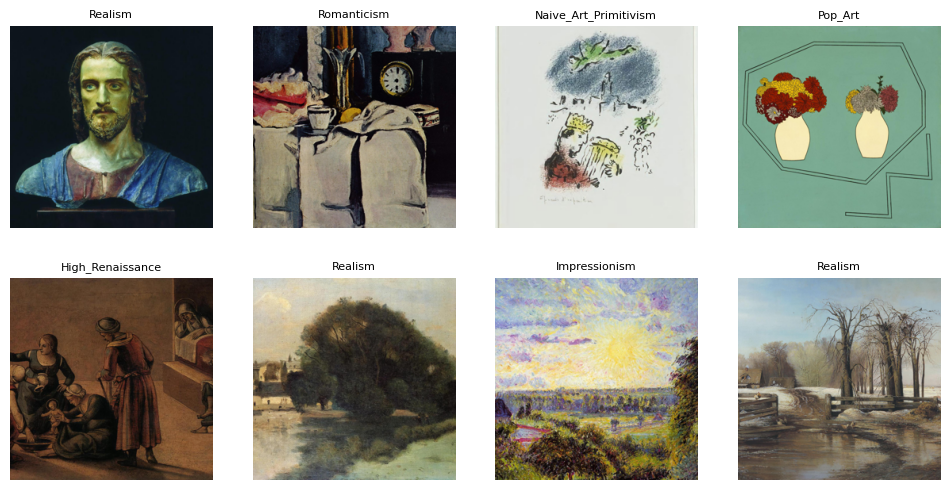

In [ ]:
K = len(names['style'])
props = {k: np.bincount(y[v], minlength=K) / len(v) for k, v in split.items()}
print('Maks. różnica udziału stylu train-test:', round(np.abs(props['train'] - props['test']).max(), 4))

images = np.load(LOCAL_NPY, mmap_mode='r')
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, i in zip(axes.flat, np.random.default_rng(0).choice(N, 8, replace=False)):
    ax.imshow(images[i]); ax.set_title(names['style'][y[i]], fontsize=8); ax.axis('off')
plt.show()

In [ ]:
shutil.copyfile(LOCAL_NPY, f'{OUT}/images.npy')
print('images.npy na Drive:', round(os.path.getsize(f'{OUT}/images.npy') / 1e9, 2), 'GB')

images.npy na Drive: 16.01 GB
